# 04 — Selección temporal interna de modelos

La comparación del notebook 03 es exploratoria y ya fue consultada. Ahora contrastamos configuraciones usando exclusivamente el bloque train: cada predictor aprende del pasado y se evalúa en una ventana posterior con siete días de separación. Buscamos una configuración para el siguiente reajuste, no un modelo final ya calibrado.

Conservamos la representación de la profesora: 432 entradas ordinales/imputadas, sin nuevos atributos, remuestreo ni categorías nativas en CatBoost. Definimos dos configuraciones por algoritmo y dos ventanas antes de ajustar: 16 entrenamientos desde cero. Seleccionamos por AP media con igual peso por ventana. Brier y log-loss raw son diagnósticos, no criterios alternativos para elegir después de ver resultados.

No consultamos métricas externas para esta selección, no ajustamos Platt y no puntuamos test. La consulta previa de validación posterior sigue siendo una limitación de desarrollo; esta etapa no la borra.

## 1. Configuración y contrato de entrada

Leemos únicamente parámetros y huellas de la corrida 03; no sus probabilidades ni su tabla comparativa. La referencia de cada algoritmo conserva aquellos parámetros. La alternativa reduce capacidad o aumenta regularización, manteniendo el número de iteraciones y la tasa de aprendizaje del boosting. Cambiar varios parámetros a la vez compara configuraciones completas y no permite atribuir la diferencia a uno solo.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import platform
import subprocess
import sys
from datetime import datetime, timezone
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir() and (p / "notebooks").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from fraud_cost.reference import read_model_frame
from fraud_cost.temporal_selection import (
    candidate_grid, expanding_folds, describe_folds, prepare_fold,
    evaluate_candidate, rank_candidates, sha256_file,
)

TABLES = ROOT / "results/tables"
FIGURES = ROOT / "results/figures"
REFERENCE_PATH = TABLES / "comparacion_modelos_config.json"
reference_record = json.loads(REFERENCE_PATH.read_text(encoding="utf-8"))
for name, expected in {**reference_record["source_sha256"], **reference_record["input_sha256"]}.items():
    if sha256_file(ROOT / name) != expected:
        raise RuntimeError(f"Cambió una entrada de la preparación 03: {name}")
FRACTIONS = (0.50, 0.75)
GAP_DAYS = 7
CANDIDATES = candidate_grid(reference_record["params"])
display(pd.DataFrame([{**c, "params": json.dumps(c["params"], ensure_ascii=False)} for c in CANDIDATES]))

,candidate,model,variant,params
0,xgboost_referencia,xgboost,referencia,"{""n_estimators"": 250, ""max_depth"": 6, ""learnin..."
1,xgboost_regularizada,xgboost,regularizada,"{""n_estimators"": 250, ""max_depth"": 4, ""learnin..."
2,lightgbm_referencia,lightgbm,referencia,"{""n_estimators"": 250, ""learning_rate"": 0.05, ""..."
3,lightgbm_regularizada,lightgbm,regularizada,"{""n_estimators"": 250, ""learning_rate"": 0.05, ""..."
4,catboost_referencia,catboost,referencia,"{""iterations"": 250, ""thread_count"": 4, ""allow_..."
5,catboost_regularizada,catboost,regularizada,"{""iterations"": 250, ""thread_count"": 4, ""allow_..."
6,logistica_referencia,logistica,referencia,"{""C"": 0.1, ""solver"": ""saga"", ""max_iter"": 500, ..."
7,logistica_regularizada,logistica,regularizada,"{""C"": 0.01, ""solver"": ""saga"", ""max_iter"": 500,..."


## 2. Solo train y dos futuros internos

El lector común recorre los CSV originales; inmediatamente retenemos solo las operaciones asignadas a train. No agregamos etiquetas ni ajustamos transformaciones en los bloques externos. Los cortes se definen por duración, no por porcentaje de filas: el número de transacciones por ventana puede diferir.

En la primera ventana entrenamos hasta el 50 % de la duración de train y evaluamos después del gap hasta el 75 %. En la segunda entrenamos hasta el 75 % y evaluamos después del gap hasta el final. El segundo pasado incluye la primera ventana evaluada, como corresponde a una ventana expansiva; cada modelo se reajusta desde cero. Ninguna operación simultánea se divide en un límite.

In [2]:
manifest_path = ROOT / "data/interim/split_manifest.parquet"
manifest = pd.read_parquet(manifest_path, columns=["TransactionID", "split"])
frame = read_model_frame(ROOT / "data/raw", manifest)
train = frame.loc[frame["split"].eq("train")].reset_index(drop=True)
del frame, manifest
gc.collect()
assert len(train) == reference_record["rows"]["train"] == 380815
folds = expanding_folds(train, fractions=FRACTIONS, gap_days=GAP_DAYS)
windows = describe_folds(train, folds)
windows.to_csv(TABLES / "seleccion_ordinal_ventanas.csv", index=False)
display(windows.drop(columns="ids_sha256"))

,fold,role,rows,frauds,fraud_rate,time_start,time_end,gap_days
0,1,fit,207920,6281,0.030209,86400,4803804,7.0
1,1,evaluate,62815,2609,0.041535,5408610,7162491,7.0
2,2,fit,290774,9761,0.033569,86400,7162491,7.0
3,2,evaluate,68759,2457,0.035734,7767318,9521218,7.0


## 3. Protocolo antes de entrenar

Registramos candidatos, ventanas y regla de selección antes de ejecutar los ajustes. Es un registro local de esta corrida, no una preregistración externa ni un diseño independiente de toda exploración previa. No usamos costo económico para desempatar: ante una igualdad exacta de AP media, aplicamos el orden lexicográfico del identificador.

Las dos alternativas de boosting reducen profundidad/hojas y aumentan controles de regularización; en logística reducimos C, que aumenta la penalización L2. Mantener 250 iteraciones no iguala capacidad ni tiempo entre algoritmos. LightGBM conserva la configuración de muestreo del 03, y CatBoost sigue recibiendo números ordinales.

In [3]:
def source_fingerprint():
    import nbformat
    notebook = nbformat.read(ROOT / "notebooks/04_seleccion_temporal_modelos.ipynb", as_version=4)
    payload = [c.source for c in notebook.cells if c.cell_type == "code"]
    return hashlib.sha256(json.dumps(payload, ensure_ascii=False).encode()).hexdigest()

protocol = {
    "created_utc": datetime.now(timezone.utc).isoformat(), "status": "planned_before_fit",
    "fractions": list(FRACTIONS), "gap_days": GAP_DAYS, "candidates": CANDIDATES,
    "selection_metric": "mean_average_precision_raw_equal_fold_weight",
    "tie_rule": "candidate_id_lexicographic_on_exact_equal_mean",
    "fold_count": len(folds), "expected_fits": len(folds) * len(CANDIDATES),
    "notebook_code_sha256": source_fingerprint(),
    "source_sha256": {name: sha256_file(ROOT / name) for name in [
        "src/fraud_cost/temporal_selection.py", "src/fraud_cost/reference.py", "requirements.txt"]},
    "reference_record_sha256": sha256_file(REFERENCE_PATH),
    "input_sha256": dict(reference_record["input_sha256"]),
    "windows_sha256": sha256_file(TABLES / "seleccion_ordinal_ventanas.csv"),
    "external_validation_used_for_current_fits_or_ranking": False,
    "prior_external_exploration_consulted": True, "test_evaluated": False,
    "calibrator_fitted": False, "costs_selected": False,
}
protocol_path = TABLES / "seleccion_ordinal_protocolo.json"
protocol_path.write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Protocolo definido: {protocol['expected_fits']} ajustes; criterio AP media interna.")

Protocolo definido: 16 ajustes; criterio AP media interna.


## 4. Ajustes y diagnósticos por ventana

Cada ventana aprende medianas y vocabularios con su propio pasado, una vez para los ocho candidatos. Para logística, cada ajuste incluye su propio escalador aprendido con esas mismas filas. No usamos eval_set, early stopping ni estadísticas aprendidas con el futuro evaluado.

Registramos categorías desconocidas por variable, tiempos y advertencias. La tabla por ajuste permite seguir el progreso y se guarda de forma parcial; solo el registro final con estado completo certifica que están las 16 combinaciones. Una advertencia de convergencia no se oculta ni convierte al ajuste en una solución óptima.

In [4]:
rows, novelty_tables, preparation = [], [], []
for fold in folds:
    print(f"Preparando ventana {fold['fold']}...", flush=True)
    A, B, y_fit, y_evaluate, novelty, details = prepare_fold(train, fold)
    assert details["n_features"] == 432
    assert details["categorical_count"] == 37 and details["numeric_count"] == 395
    novelty_tables.append(novelty)
    preparation.append({"fold": fold["fold"], **details})
    for candidate in CANDIDATES:
        print(f"Ventana {fold['fold']}: {candidate['candidate']}", flush=True)
        result = evaluate_candidate(candidate, A, B, y_fit, y_evaluate)
        rows.append({"fold": fold["fold"], **result})
        pd.DataFrame(rows).to_csv(TABLES / "seleccion_ordinal_folds.csv", index=False)
        print(f"  AP={result['average_precision']:.5f}; ajuste={result['fit_seconds']:.1f}s; "
              f"advertencia de convergencia={result['convergence_warning']}", flush=True)
    del A, B, y_fit, y_evaluate
    gc.collect()
results = pd.DataFrame(rows)
novelty_results = pd.concat(novelty_tables, ignore_index=True)
novelty_results.to_csv(TABLES / "seleccion_ordinal_categorias.csv", index=False)
display(results[["fold", "candidate", "average_precision", "brier_raw", "log_loss_raw", "convergence_warning"]])

Preparando ventana 1...


Ventana 1: xgboost_referencia


  AP=0.59096; ajuste=25.4s; advertencia de convergencia=False


Ventana 1: xgboost_regularizada


  AP=0.55844; ajuste=18.2s; advertencia de convergencia=False


Ventana 1: lightgbm_referencia


... (25 outputs left out)

  AP=0.31666; ajuste=281.9s; advertencia de convergencia=False


Ventana 2: logistica_regularizada


  AP=0.31666; ajuste=280.7s; advertencia de convergencia=False


,fold,candidate,average_precision,brier_raw,log_loss_raw,convergence_warning
0,1,xgboost_referencia,0.590961,0.024709,0.101355,False
1,1,xgboost_regularizada,0.558436,0.025956,0.106147,False
2,1,lightgbm_referencia,0.621542,0.024035,0.097897,False
3,1,lightgbm_regularizada,0.605426,0.024321,0.099107,False
4,1,catboost_referencia,0.557387,0.025945,0.107750,False
5,1,catboost_regularizada,0.532426,0.026928,0.111383,False
6,1,logistica_referencia,0.424720,0.030617,0.126579,False
7,1,logistica_regularizada,0.424704,0.030617,0.126582,False
8,2,xgboost_referencia,0.518759,0.023352,0.097713,False
9,2,xgboost_regularizada,0.485620,0.024331,0.102144,False


## 5. Selección y estabilidad descriptiva

Promediamos las dos AP con igual peso por ventana. No elegimos la mejor ventana de cada candidato ni mezclamos estas cifras con AP de validación posterior del 03. La prevalencia cambia entre periodos y afecta la lectura de AP.

La dispersión entre dos ventanas describe sensibilidad temporal, no un intervalo de confianza ni evidencia de significación. La búsqueda es pequeña: el ganador es la configuración elegida dentro de estos ocho candidatos, no el mejor modelo posible para IEEE-CIS.

,candidate,model,variant,mean_ap,std_ap,min_ap,max_ap,mean_brier_raw,mean_log_loss_raw,fit_seconds_total,convergence_warnings
0,lightgbm_referencia,lightgbm,referencia,0.58812,0.04727,0.55469,0.62154,0.02329,0.09593,30.83991,0
1,lightgbm_regularizada,lightgbm,regularizada,0.56857,0.05213,0.53171,0.60543,0.02369,0.09772,24.54230,0
2,xgboost_referencia,xgboost,referencia,0.55486,0.05105,0.51876,0.59096,0.02403,0.09953,60.46777,0
3,xgboost_regularizada,xgboost,regularizada,0.52203,0.05149,0.48562,0.55844,0.02514,0.10415,47.76745,0
4,catboost_referencia,catboost,referencia,0.51511,0.05979,0.47283,0.55739,0.02526,0.10597,82.29636,0
5,catboost_regularizada,catboost,regularizada,0.49123,0.05827,0.45002,0.53243,0.02609,0.10920,61.50828,0
6,logistica_referencia,logistica,referencia,0.37069,0.07641,0.31666,0.42472,0.02973,0.12467,500.19845,0
7,logistica_regularizada,logistica,regularizada,0.37068,0.07640,0.31666,0.42470,0.02973,0.12467,499.45494,0


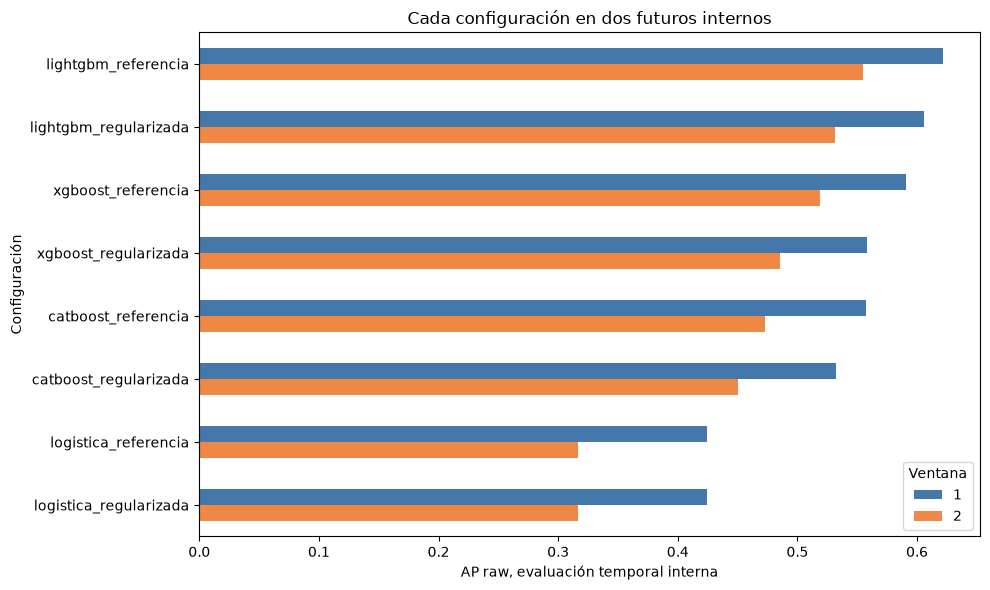

Configuración seleccionada dentro de train: lightgbm_referencia
Falta reajustar con todo train, calibrar y evaluar sus decisiones económicas.


In [5]:
summary = rank_candidates(results, CANDIDATES, len(folds))
summary.to_csv(TABLES / "seleccion_ordinal_resumen.csv", index=False)
display(summary.round(5))
winner_id = summary.iloc[0].candidate
selected = next(c for c in CANDIDATES if c["candidate"] == winner_id)
plot = results.pivot(index="candidate", columns="fold", values="average_precision").reindex(summary.candidate)
ax = plot.plot.barh(figsize=(10, 6), color=["#4477AA", "#EE8844"])
ax.invert_yaxis()
ax.set(xlabel="AP raw, evaluación temporal interna", ylabel="Configuración", title="Cada configuración en dos futuros internos")
ax.legend(title="Ventana")
plt.tight_layout()
plt.savefig(FIGURES / "seleccion_ordinal_ap.png", dpi=160, bbox_inches="tight")
plt.show()
print("Configuración seleccionada dentro de train:", winner_id)
print("Falta reajustar con todo train, calibrar y evaluar sus decisiones económicas.")

## 6. Registro y continuación

Exportamos una configuración, no un predictor final. Los modelos de las ventanas no se reutilizan como si estuvieran entrenados con todo train. Completamos los 16 ajustes y seleccionamos LightGBM referencia con AP media 0,588117: lidera ambas ventanas. La etapa 05 verificará si puede reutilizar su ajuste coincidente del 03 y su propio Platt; si no, reajustará con todo train y calibrará solo en validación temprana. El diagnóstico posterior sigue siendo desarrollo.

Se mantienen las doce discrepancias de tipos documentadas y la limitación de CatBoost con ordinal. No corregimos esos aspectos a mitad de la comparación. El test sigue sin puntuarse y Ca no participa en la selección.

Si recuperamos artefactos mediante una nueva corrida, exigimos el recibo y la evidencia de `verify_reference_artifacts`: equivalencia numérica no significa identidad binaria. Los registros y las celdas ejecutables del 04 permanecen intactos. El informe de esta etapa contiene el ranking completo y sus límites.

In [6]:
outputs = ["results/tables/seleccion_ordinal_ventanas.csv", "results/tables/seleccion_ordinal_folds.csv",
           "results/tables/seleccion_ordinal_resumen.csv", "results/tables/seleccion_ordinal_categorias.csv",
           "results/figures/seleccion_ordinal_ap.png"]
if source_fingerprint() != protocol["notebook_code_sha256"]:
    raise RuntimeError("El código del notebook cambió durante la corrida")
for name, expected in {**protocol["source_sha256"], **protocol["input_sha256"]}.items():
    if sha256_file(ROOT / name) != expected:
        raise RuntimeError(f"Cambió una fuente o entrada durante la corrida: {name}")
record = {
    "completed_utc": datetime.now(timezone.utc).isoformat(), "status": "complete",
    "protocol_sha256": sha256_file(protocol_path), "notebook_code_sha256": source_fingerprint(),
    "selected_candidate": selected, "selection_metric": protocol["selection_metric"],
    "selected_mean_ap": float(summary.iloc[0].mean_ap), "fit_count": len(results),
    "preparation": preparation, "test_evaluated": False, "final_model_fitted": False,
    "calibrator_fitted": False, "costs_selected": False,
    "external_validation_used_for_current_fits_or_ranking": False,
    "prior_external_exploration_consulted": True,
    "python": platform.python_version(),
    "versions": {p: version(p) for p in ["numpy", "pandas", "scikit-learn", "xgboost", "lightgbm", "catboost"]},
    "git_base_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip(),
    "working_tree_dirty": bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=ROOT, text=True).strip()),
    "output_sha256": {p: sha256_file(ROOT / p) for p in outputs},
}
(TABLES / "seleccion_ordinal_config.json").write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding="utf-8")
print("Registro completo; test sin puntuar y predictor final todavía sin reajustar.")

Registro completo; test sin puntuar y predictor final todavía sin reajustar.
